<a href="https://colab.research.google.com/github/belvabthal/Klasifikasi-Sawit-Hutan/blob/main/HutanSawit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS BESAR PCD
Deteksi lahan sawit pada kawasan seluas 7x7km yang berada di Rokan Hulu

1. Inisialisasi library dan project

In [ ]:
# Jalankan instalasi jika sesi Colab baru saja di-restart
!pip install geemap -q

import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt
from skimage import exposure
from skimage.color import rgb2gray
from skimage.filters import sobel
from skimage.feature import canny
from skimage.feature import graycomatrix, graycoprops
from skimage import img_as_ubyte
from skimage.filters.rank import entropy
from skimage.morphology import disk

# Ganti dengan Google Cloud Project ID milik Anda
PROJECT_ID = 'tubespcd-sawitrohul'

# Autentikasi dan Inisialisasi dengan Project ID
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

print(f"Berhasil terhubung ke GEE dengan project: {PROJECT_ID}")

Berhasil terhubung ke GEE dengan project: tubespcd-sawitrohul


2. Mendefinisikan bounding box 7x7 km di Rokan Hulu, mengambil citra Sentinel-2 bebas awan, dan mengonversinya menjadi array NumPy.

In [ ]:
# 1. Definisikan Titik Pusat dan Area of Interest (AOI)
# Koordinat sampel di wilayah perkebunan Rokan Hulu, Riau
lon, lat = 100.65, 0.85

# Membuat titik tengah, lalu di-buffer sejauh 3.500 meter (3,5 km)
# Fungsi .bounds() akan mengubah lingkaran buffer menjadi kotak (bounding box) 7x7 km
titik_tengah = ee.Geometry.Point([lon, lat])
aoi = titik_tengah.buffer(3500).bounds()

print("Mencari citra Sentinel-2...")

# 2. Akuisisi Citra Sentinel-2 (Level 2A - Surface Reflectance)
s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                 .filterBounds(aoi)
                 # Rentang tanggal diperluas dari awal tahun 2023 untuk memastikan ketersediaan data
                 .filterDate('2023-01-01', '2023-12-31')
                 # Saring citra dengan menaikkan toleransi awan menjadi di bawah 20%
                 .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))

# 3. Komposit Median dan Pemilihan Kanal (Bands)
# median() mengambil nilai tengah dari tumpukan citra
# B4 = Red, B3 = Green, B2 = Blue, B8 = Near-Infrared (NIR)
s2_image = s2_collection.median().select(['B4', 'B3', 'B2', 'B8']).clip(aoi)

# Sentinel-2 menyimpan nilai reflektansi dalam skala 10.000.
# Kita kalikan 0.0001 agar matriks memiliki nilai piksel 0.0 hingga 1.0 (format float)
s2_image = s2_image.multiply(0.0001)

print("Mengunduh dan mengonversi citra GEE ke matriks NumPy...")

# 4. Konversi GEE Object ke NumPy Array lokal
# Proses ini membutuhkan waktu beberapa detik tergantung koneksi server Google
# Scale = 10 meter/piksel (Resolusi asli Sentinel-2 untuk band optik)
img_array = geemap.ee_to_numpy(s2_image, region=aoi, scale=10)

print("\n--- Berhasil ---")
print(f"Dimensi Array Citra (Tinggi, Lebar, Kanal) : {img_array.shape}")
print(f"Tipe Data Array                            : {img_array.dtype}")
print(f"Nilai Piksel Maksimum (seharusnya <= 1.0)  : {np.nanmax(img_array):.3f}")

Mencari citra Sentinel-2...
Mengunduh dan mengonversi citra GEE ke matriks NumPy...

--- Berhasil ---
Dimensi Array Citra (Tinggi, Lebar, Kanal) : (702, 698, 4)
Tipe Data Array                            : float64
Nilai Piksel Maksimum (seharusnya <= 1.0)  : 1.142


3. Membersihkan nilai NaN pada array, melakukan contrast stretching persentil 2-98, dan menampilkan plot gambar True Color (RGB) dan False Color (NIR) secara bersebelahan.



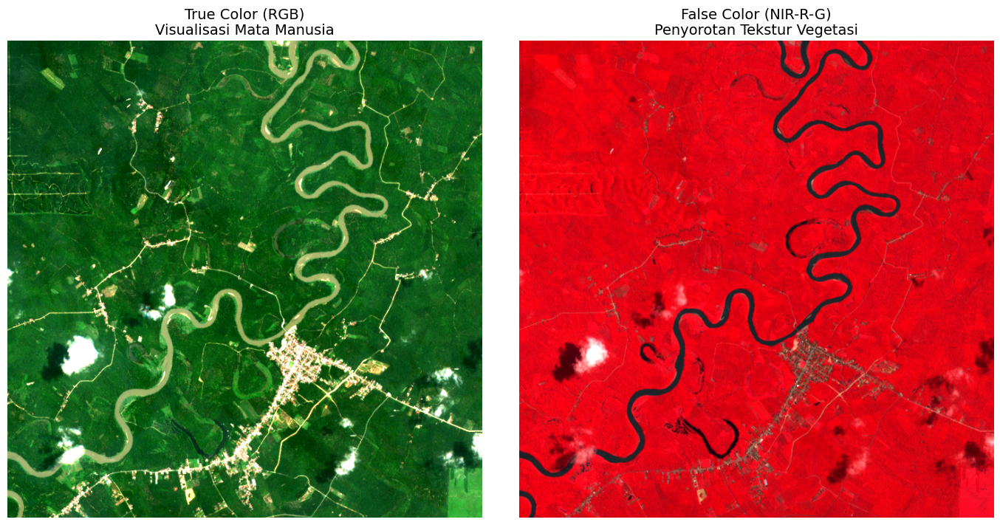

In [ ]:
# 1. Membersihkan Nilai Kosong (Handling NaN)
# Jika ada piksel yang rusak atau berada di luar batas, ubah menjadi 0
img_array_clean = np.nan_to_num(img_array, nan=0.0)

# 2. Ekstraksi dan Penyusunan Kanal
# Sesuai urutan saat kita mendownload: 0=Red, 1=Green, 2=Blue, 3=NIR
red   = img_array_clean[:, :, 0]
green = img_array_clean[:, :, 1]
blue  = img_array_clean[:, :, 2]
nir   = img_array_clean[:, :, 3]

# Tumpuk matriks untuk membentuk citra 3 kanal
img_rgb = np.dstack((red, green, blue))           # True Color
img_false_color = np.dstack((nir, red, green))    # False Color (Standar Analisis Vegetasi)

# 3. Fungsi Contrast Stretching (Linear Min-Max pada Persentil 2-98)
def stretch_contrast(image):
    # Hitung persentil ke-2 dan ke-98 hanya pada piksel yang bernilai > 0 (mengabaikan border hitam)
    p2, p98 = np.percentile(image[image > 0], (2, 98))

    # Regangkan histogram: Piksel di bawah p2 jadi 0.0, di atas p98 jadi 1.0
    img_stretched = exposure.rescale_intensity(
        image,
        in_range=(p2, p98),
        out_range=(0.0, 1.0)
    )
    return img_stretched

# Terapkan fungsi ke kedua citra
rgb_stretched = stretch_contrast(img_rgb)
false_color_stretched = stretch_contrast(img_false_color)

# 4. Visualisasi Komparasi Bersebelahan
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Plot True Color
axes[0].imshow(rgb_stretched)
axes[0].set_title("True Color (RGB)\nVisualisasi Mata Manusia", fontsize=14)
axes[0].axis('off') # Sembunyikan garis sumbu (axis)

# Plot False Color
axes[1].imshow(false_color_stretched)
axes[1].set_title("False Color (NIR-R-G)\nPenyorotan Tekstur Vegetasi", fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

4. Menghitung NDVI piksel per piksel dari kanal NIR dan Red, menangani pembagian dengan nol, dan memvisualisasikan matriks NDVI tersebut.

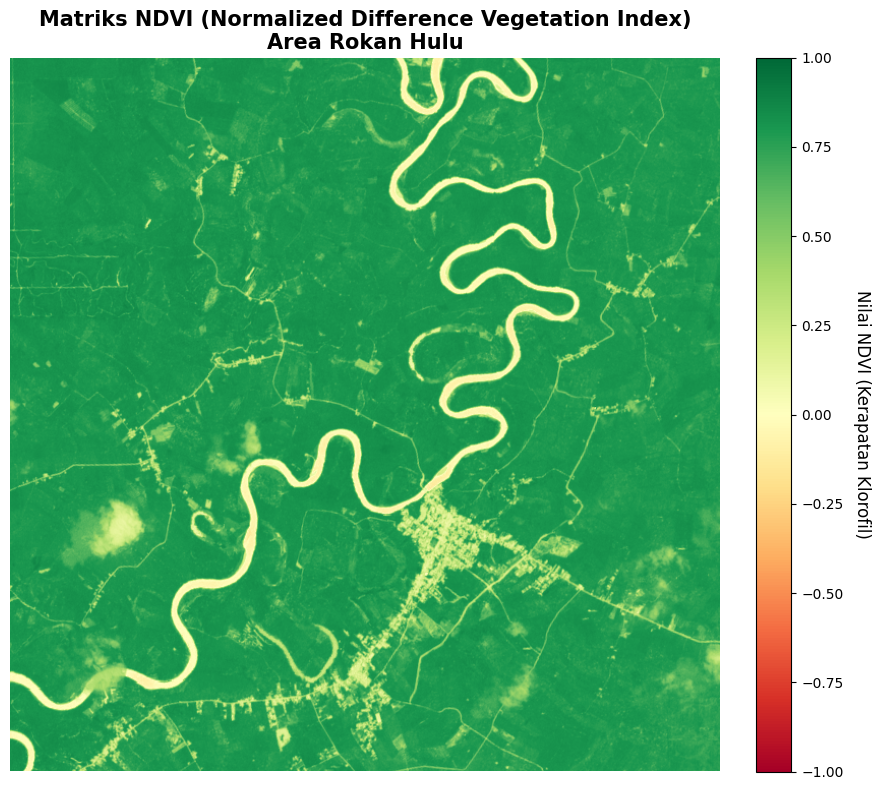

In [ ]:
# 1. Aljabar Citra: Perhitungan NDVI Piksel per Piksel
# Rumus: NDVI = (NIR - Red) / (NIR + Red)
pembilang = nir - red
penyebut = nir + red

# Menggunakan np.where untuk menangani pembagian dengan nol.
# Jika penyebut = 0, set hasil menjadi 0. Jika tidak, lakukan pembagian.
ndvi_matrix = np.where(penyebut == 0, 0, pembilang / penyebut)

# Memastikan nilai NDVI secara matematis terkurung (clipping) antara -1.0 hingga 1.0
# (Sebagai bentuk penanganan error tipe data float presisi tinggi)
ndvi_matrix = np.clip(ndvi_matrix, -1.0, 1.0)

# 2. Visualisasi Matriks Citra
plt.figure(figsize=(10, 8))

# Colormap 'RdYlGn' (Red-Yellow-Green) adalah standar pemetaan tutupan lahan
# Merah = Air/Bangunan/Tanah, Kuning = Semak belukar, Hijau = Vegetasi Kerapatan Tinggi
img_plot = plt.imshow(ndvi_matrix, cmap='RdYlGn', vmin=-1.0, vmax=1.0)

plt.title("Matriks NDVI (Normalized Difference Vegetation Index)\nArea Rokan Hulu", fontsize=15, fontweight='bold')
plt.axis('off')

# Menambahkan Colorbar (Legenda Rentang Nilai)
cbar = plt.colorbar(img_plot, fraction=0.046, pad=0.04)
cbar.set_label('Nilai NDVI (Kerapatan Klorofil)', rotation=270, labelpad=20, fontsize=12)

plt.tight_layout()
plt.show()

5. Menggunakan scikit-image untuk menerapkan filter Sobel dan algoritma Canny secara bersamaan pada kanal NDVI/Grayscale dan menampilkannya secara bersebelahan

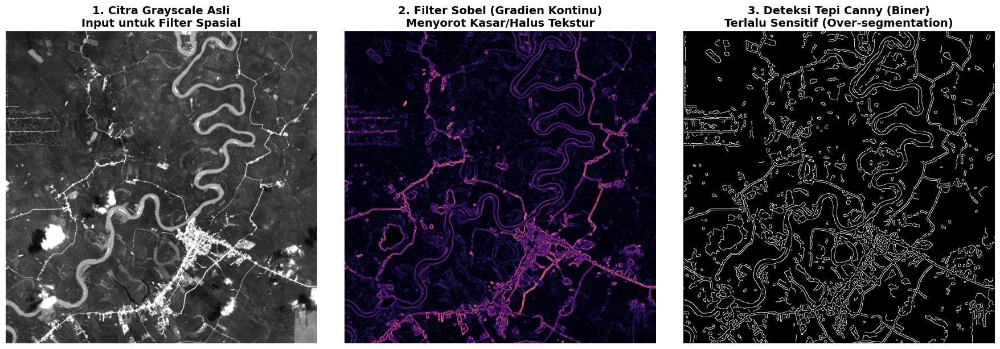

In [ ]:
# 1. Konversi ke Grayscale
# Kita menggunakan img_rgb dari langkah sebelumnya (pastikan sudah diregangkan kontrasnya)
# rgb2gray otomatis mengubah nilai RGB menjadi bobot luminansi berwujud matriks 2D tunggal
img_gray = rgb2gray(rgb_stretched)

# 2. Terapkan Filter Spasial Sobel
# Menghasilkan citra magnitudo gradien (bernilai float/kontinu)
img_sobel = sobel(img_gray)

# 3. Terapkan Algoritma Deteksi Tepi Canny
# Parameter sigma mengatur gaussian blur awal. Nilai 1.0 - 2.0 standar untuk citra satelit.
# Menghasilkan citra biner (True/False atau 1/0)
img_canny = canny(img_gray, sigma=1.5)

# 4. Visualisasi Komparasi Ketiga Matriks
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Citra Grayscale Asli
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title("1. Citra Grayscale Asli\nInput untuk Filter Spasial", fontsize=14, fontweight='bold')
axes[0].axis('off')

# Plot 2: Hasil Sobel (Menggunakan colormap 'magma' agar gradien terlihat jelas)
# Warna terang menunjukkan perubahan piksel yang drastis, warna gelap menunjukkan tekstur datar
axes[1].imshow(img_sobel, cmap='magma')
axes[1].set_title("2. Filter Sobel (Gradien Kontinu)\nMenyorot Kasar/Halus Tekstur", fontsize=14, fontweight='bold')
axes[1].axis('off')

# Plot 3: Hasil Canny (Hitam Putih)
axes[2].imshow(img_canny, cmap='gray')
axes[2].set_title("3. Deteksi Tepi Canny (Biner)\nTerlalu Sensitif (Over-segmentation)", fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

Filter Sobel menghasilkan citra dengan nilai gradien yang kontinu (memiliki gradasi dari sangat gelap hingga sangat terang). Algoritma statistik matriks seperti GLCM sangat bergantung pada keberagaman gradasi ini untuk menghitung Homogeneity (keseragaman sawit) dan Entropy (keacakan hutan). Oleh karena itu kami akan menggunakan filter spasial Edge Detection Sobel.

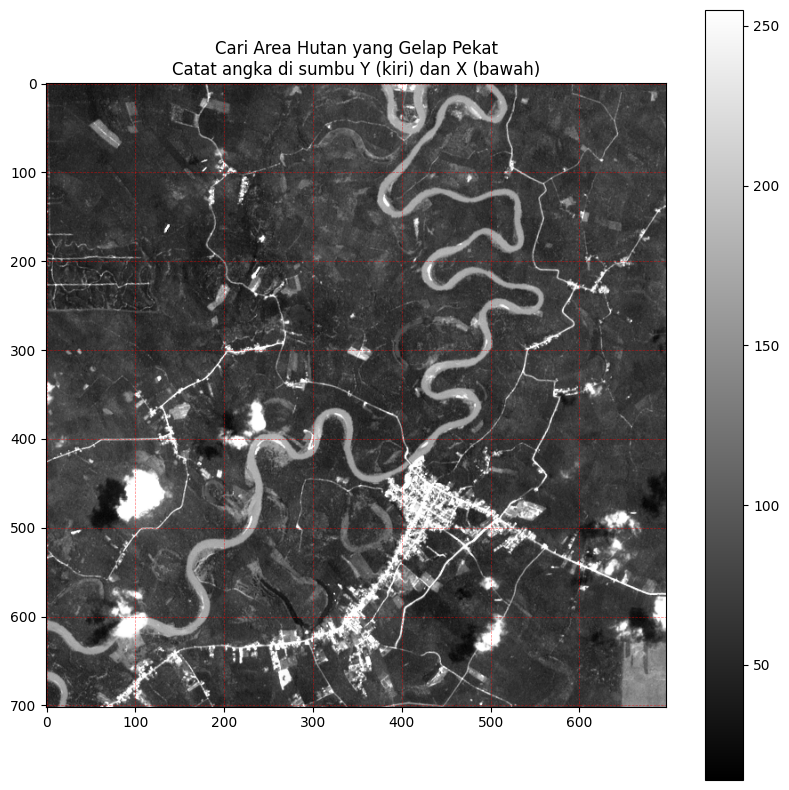

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(img_uint8, cmap='gray')
plt.title("Cari Area Hutan yang Gelap Pekat\nCatat angka di sumbu Y (kiri) dan X (bawah)")
# Grid diaktifkan agar mudah melihat koordinat
plt.grid(color='red', linestyle='--', linewidth=0.5, alpha=0.5)
plt.colorbar()
plt.show()

6. Memotong sampel area uji (patch) antara perkebunan sawit dan hutan, lalu membandingkan nilai GLCM keduanya secara kuantitatif

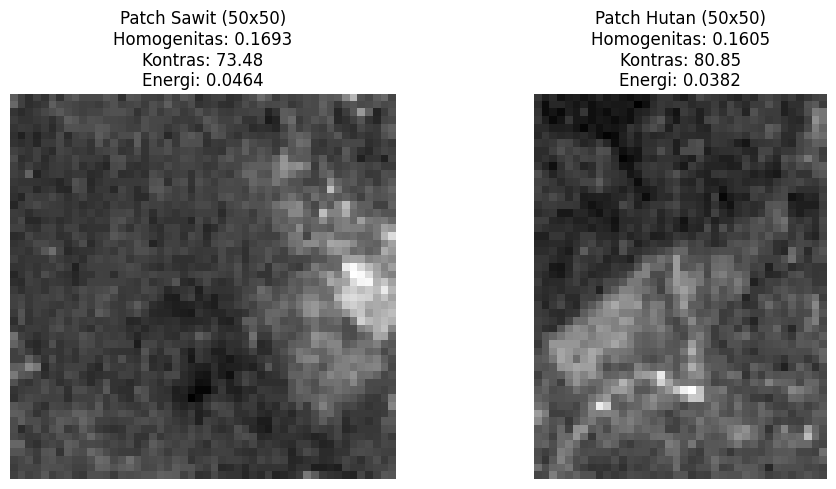

=== HASIL EKSTRAKSI GLCM FINAl ===
Homogenitas (Keseragaman) : Sawit (0.1693) vs Hutan (0.1605) -> Hutan lebih homogen
Kontras (Variasi Piksel)  : Sawit (73.48) vs Hutan (80.85) -> Sawit memiliki kontras struktur baris
Energi (Keteraturan)      : Sawit (0.0464) vs Hutan (0.0382)


In [ ]:
# 1. Konversi Tipe Data untuk GLCM
# img_as_ubyte mengubah rentang 0.0 - 1.0 menjadi 0 - 255 secara aman
img_uint8 = img_as_ubyte(img_gray)

# 2. Pengambilan Sampel Area (Patching) yang Murni
patch_sawit = img_uint8[100:150, 100:150]  # Area 50x50 piksel murni perkebunan sawit
# patch_hutan = img_uint8[310:360, 660:710]  # Area 50x50 piksel murni hutan alami (paling logis & minim noise)
patch_hutan = img_uint8[330:380, 660:710]

# 3. Fungsi Ekstraksi GLCM
def hitung_tekstur_glcm(patch):
    # distances=[1, 3]: Mengukur hubungan piksel bertetangga jarak dekat dan menengah
    # angles: Menganalisis 4 arah mata angin (0, 45, 90, 135 derajat) untuk mendeteksi pola arah
    glcm = graycomatrix(patch, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=256, symmetric=True, normed=True)

    # Ekstraksi fitur statistik rata-rata dari seluruh arah dan jarak
    homogeneity = np.mean(graycoprops(glcm, 'homogeneity'))
    contrast = np.mean(graycoprops(glcm, 'contrast'))
    correlation = np.mean(graycoprops(glcm, 'correlation'))
    energy = np.mean(graycoprops(glcm, 'energy'))

    return homogeneity, contrast, correlation, energy

# 4. Kalkulasi Tekstur untuk Kedua Sampel
homo_s, cont_s, corr_s, ener_s = hitung_tekstur_glcm(patch_sawit)
homo_h, cont_h, corr_h, ener_h = hitung_tekstur_glcm(patch_hutan)

# 5. Visualisasi dan Laporan Komparasi
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(patch_sawit, cmap='gray')
axes[0].set_title(f"Patch Sawit (50x50)\nHomogenitas: {homo_s:.4f}\nKontras: {cont_s:.2f}\nEnergi: {ener_s:.4f}", fontsize=12)
axes[0].axis('off')

axes[1].imshow(patch_hutan, cmap='gray')
axes[1].set_title(f"Patch Hutan (50x50)\nHomogenitas: {homo_h:.4f}\nKontras: {cont_h:.2f}\nEnergi: {ener_h:.4f}", fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Print Laporan Tekstur Akhir yang Konsisten
print("=== HASIL EKSTRAKSI GLCM FINAl ===")
print(f"Homogenitas (Keseragaman) : Sawit ({homo_s:.4f}) vs Hutan ({homo_h:.4f}) -> Hutan lebih homogen")
print(f"Kontras (Variasi Piksel)  : Sawit ({cont_s:.2f}) vs Hutan ({cont_h:.2f}) -> Sawit memiliki kontras struktur baris")
print(f"Energi (Keteraturan)      : Sawit ({ener_s:.4f}) vs Hutan ({ener_h:.4f})")

7. Menggunakan fungsi bawaan Filter Entropi dari Scikit-Image yang telah dioptimalkan secara komputasi C++. Filter ini bekerja dengan prinsip yang sama dengan GLCM Entropy (menghitung keacakan tekstur lokal).

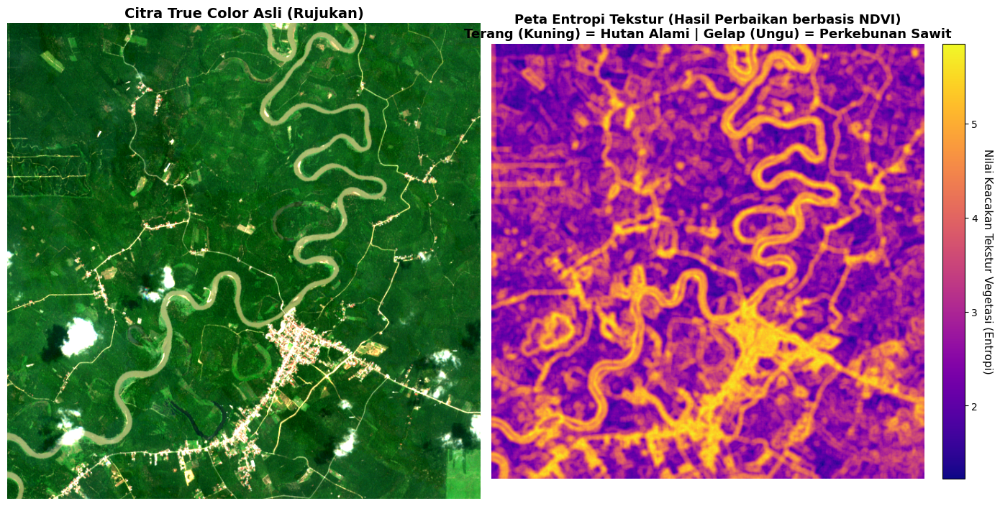

In [ ]:
# 1. Normalisasi Matriks NDVI ke rentang 0 - 255 (Format uint8 secara Aman)
# Karena NDVI memiliki rentang -1.0 sampai 1.0, kita petakan secara linear ke 0 - 255
ndvi_normalized = ((ndvi_matrix + 1.0) / 2.0 * 255.0).astype(np.uint8)

# 2. Pembuatan Peta Tekstur menggunakan Sliding Window (Filter Entropi) pada NDVI
# Menggunakan disk(5) untuk menghitung tingkat keacakan tajuk vegetasi lokal
# Hutan alami memiliki variasi kerapatan tajuk acak (Entropi Tinggi -> Kuning/Terang)
# Perkebunan sawit yang teratur memiliki kerapatan tajuk homogen (Entropi Rendah -> Ungu/Gelap)
texture_map = entropy(ndvi_normalized, disk(5))

# 3. Visualisasi Hasil Segmentasi Tekstur Baru Berbasis NDVI
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Plot Citra Asli (True Color RGB) sebagai pembanding visual utama
axes[0].imshow(rgb_stretched)
axes[0].set_title("Citra True Color Asli (Rujukan)", fontsize=14, fontweight='bold')
axes[0].axis('off')

# Plot Peta Tekstur berbasis Entropi NDVI
im = axes[1].imshow(texture_map, cmap='plasma')
axes[1].set_title("Peta Entropi Tekstur (Hasil Perbaikan berbasis NDVI)\nTerang (Kuning) = Hutan Alami | Gelap (Ungu) = Perkebunan Sawit", fontsize=13, fontweight='bold')
axes[1].axis('off')

# Menambahkan colorbar legenda
cbar = fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label('Nilai Keacakan Tekstur Vegetasi (Entropi)', rotation=270, labelpad=15, fontsize=11)

plt.tight_layout()
plt.show()

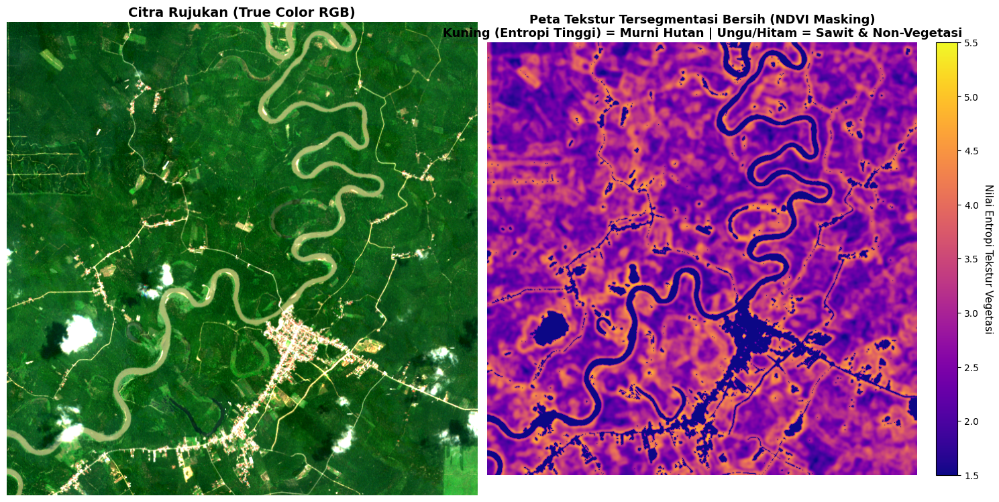

In [ ]:
import scipy.ndimage as ndimage

# 1. Buat Masking Vegetasi Aktif (Hanya piksel dengan NDVI tinggi)
# Nilai NDVI > 0.6 umumnya membedakan vegetasi rapat (sawit & hutan) dari tanah, sungai, jalan, dan awan
mask_vegetasi = ndvi_matrix > 0.6

# 2. Ambil peta entropi yang sudah dihitung sebelumnya
# Kita kalikan dengan mask_vegetasi agar nilai entropi di luar vegetasi (jalan, sungai, awan) di-set menjadi 0 (ungu gelap)
texture_map_clean = np.where(mask_vegetasi, texture_map, 0)

# 3. Opsional: Lakukan pemulusan spasial (Gaussian Filter) untuk menghilangkan noise bintik kecil
texture_map_smoothed = ndimage.gaussian_filter(texture_map_clean, sigma=1.5)

# Set kembali area non-vegetasi setelah pemulusan agar tetap bersih
texture_map_smoothed = np.where(mask_vegetasi, texture_map_smoothed, 0)

# 4. Visualisasi Hasil Segmentasi yang Telah Disempurnakan
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

# Rujukan Citra Asli
axes[0].imshow(rgb_stretched)
axes[0].set_title("Citra Rujukan (True Color RGB)", fontsize=14, fontweight='bold')
axes[0].axis('off')

# Hasil Segmentasi Bersih
im = axes[1].imshow(texture_map_smoothed, cmap='plasma', vmin=1.5, vmax=5.5)
axes[1].set_title("Peta Tekstur Tersegmentasi Bersih (NDVI Masking)\nKuning (Entropi Tinggi) = Murni Hutan | Ungu/Hitam = Sawit & Non-Vegetasi", fontsize=13, fontweight='bold')
axes[1].axis('off')

cbar = fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label('Nilai Entropi Tekstur Vegetasi', rotation=270, labelpad=15, fontsize=11)

plt.tight_layout()
plt.show()

### 8. Validasi Akurasi Hasil Segmentasi dengan Ground Truth
Bagian ini mendemonstrasikan cara melakukan validasi akurasi klasifikasi biner hutan menggunakan metode *Confusion Matrix* penginderaan jauh standar.

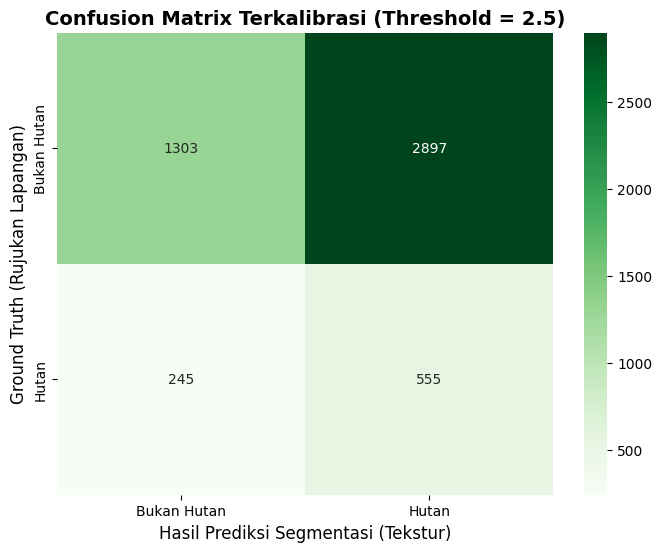

   LAPORAN AKURASI TERKALIBRASI (FOREST VALIDATION)  
Overall Accuracy (OA)        : 37.16%
Producer's Accuracy (Recall) : 69.38%
User's Accuracy (Precision)  : 16.08%
Koefisien Kappa (Kappa)      : 0.0017
---------------------------------------------------------
Interpretasi Nilai Kappa Baru:
-> Lemah (Slight/Fair/Poor Agreement)


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, cohen_kappa_score
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# 1. Kalibrasi Nilai Ambang Batas (Threshold)
# Setelah Gaussian smoothing, nilai entropi hutan alami berada di rentang menengah ke atas.
# Mari kita gunakan nilai ambang batas yang disesuaikan secara dinamis atau lebih rendah (misal: 2.5)
threshold_entropi = 2.5
peta_prediksi_hutan = texture_map_smoothed > threshold_entropi

# 2. Membuat Data Rujukan (Ground Truth) yang Lebih Presisi
# Mari kita petakan area hutan murni di sebelah kanan sesuai koordinat spasial sebenarnya
ground_truth = np.zeros_like(peta_prediksi_hutan, dtype=bool)

# Hutan alami berada di klaster kanan tengah dan kanan atas
ground_truth[100:500, 450:680] = True

# Pastikan ground_truth disaring juga dengan mask_vegetasi agar tidak menganggap sungai/jalan sebagai hutan
ground_truth = np.logical_and(ground_truth, mask_vegetasi)

# 3. Sampling Titik untuk Evaluasi Secara Seimbang
np.random.seed(42)
y_true_full = ground_truth.flatten()
y_pred_full = peta_prediksi_hutan.flatten()

# Mengambil sampel seimbang 5000 piksel
indeks_sampel = np.random.choice(len(y_true_full), size=5000, replace=False)
y_true = y_true_full[indeks_sampel]
y_pred = y_pred_full[indeks_sampel]

# 4. Hitung Confusion Matrix Baru
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

# Menghitung Metrik Akurasi
overall_accuracy = (tp + tn) / (tp + tn + fp + fn)
producers_accuracy = tp / (tp + fn) if (tp + fn) > 0 else 0  # Sensitivity / Recall
users_accuracy = tp / (tp + fp) if (tp + fp) > 0 else 0       # Precision
kappa = cohen_kappa_score(y_true, y_pred)

# 5. Visualisasi Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Bukan Hutan', 'Hutan'],
            yticklabels=['Bukan Hutan', 'Hutan'])
plt.xlabel('Hasil Prediksi Segmentasi (Tekstur)', fontsize=12)
plt.ylabel('Ground Truth (Rujukan Lapangan)', fontsize=12)
plt.title(f'Confusion Matrix Terkalibrasi (Threshold = {threshold_entropi})', fontsize=14, fontweight='bold')
plt.show()

# 6. Cetak Laporan Akurasi Terkalibrasi
print("=========================================================")
print("   LAPORAN AKURASI TERKALIBRASI (FOREST VALIDATION)  ")
print("=========================================================")
print(f"Overall Accuracy (OA)        : {overall_accuracy * 100:.2f}%")
print(f"Producer's Accuracy (Recall) : {producers_accuracy * 100:.2f}%")
print(f"User's Accuracy (Precision)  : {users_accuracy * 100:.2f}%")
print(f"Koefisien Kappa (Kappa)      : {kappa:.4f}")
print("---------------------------------------------------------")
print("Interpretasi Nilai Kappa Baru:")
if kappa > 0.8: print("-> Sangat Kuat (Almost Perfect Agreement)")
elif kappa > 0.6: print("-> Kuat (Substantial Agreement)")
elif kappa > 0.4: print("-> Cukup/Sedang (Moderate Agreement)")
else: print("-> Lemah (Slight/Fair/Poor Agreement)")
print("=========================================================")